In [1]:
import sys
sys.path.append("..")
import torch
import imageio.v3 as iio
from torchmetrics.image import StructuralSimilarityIndexMeasure
import matplotlib.pyplot as plt
from src.inr import SparseImageINR
from src.models import RandomFourierFeatures
from torch.optim import Adam

In [2]:
def load_img(img_path):
    img = iio.imread(img_path) / 255.0
    center = img.shape[0] // 2, img.shape[1] // 2
    img_size = 512
    img = img[
        center[0] - img_size // 2 : center[0] + img_size // 2,
        center[1] - img_size // 2 : center[1] + img_size // 2,
    ]
    img = torch.tensor(img).to(torch.float)
    #img = torch.permute(img, (2,0,1))
    return img

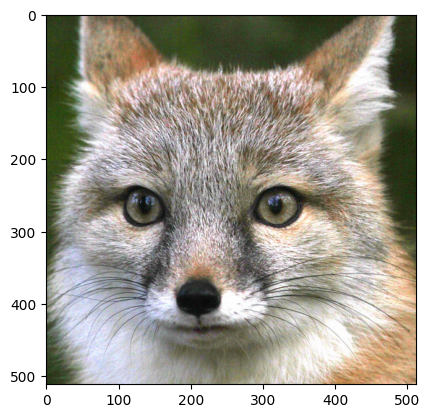

In [3]:
fox = load_img("../fox.jpg")
fox_reshaped = fox.permute(2,0,1).view(1,3,512,512)
#fox_degraded = 0.2*fox

plt.imshow(fox)

#plt.figure()
#plt.imshow(fox_degraded[0].permute(1,2,0))

In [4]:
device = torch.device("cpu")
model = RandomFourierFeatures(2, 256, 256, 3, 3, 5).to(device)
optim = Adam(model.parameters())
inr = SparseImageINR(target_image=fox, guide_image=None, channel_dim=2, normalization_shift="individual_min_max", normalization_scale="individual_min_max", sparsity=1, test_grid_skip=2, model=model,
                     target_optimizer=optim, guide_optimizer=None, criterion=torch.nn.MSELoss(), metrics={"rescaled_loss": torch.nn.MSELoss()}, full_image_metrics={},
                     batch_size="full", shuffle=True, device=device)
#inr = SparseImageINR(fox, True, 2, 0.01, 2, model, optim, torch.nn.MSELoss(), {}, "full", True, device)

In [5]:
_ = inr.fit(10, False, False)

100%|███████████████████████████████████████████| 10/10 [00:27<00:00,  2.72s/it]


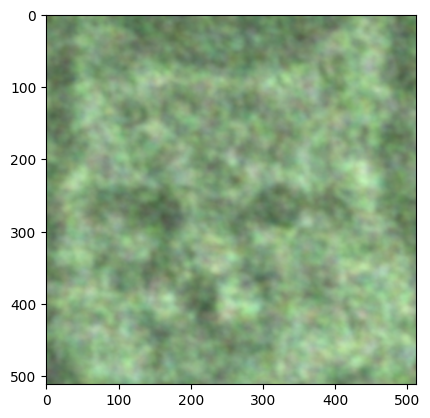

In [6]:
degraded_fox = inr.reconstructed_target
degraded_fox_reshaped = degraded_fox.permute(2,0,1).view(1,3,512,512)
plt.imshow(degraded_fox)

In [9]:
fox_reshaped.shape

torch.Size([1, 3, 512, 512])

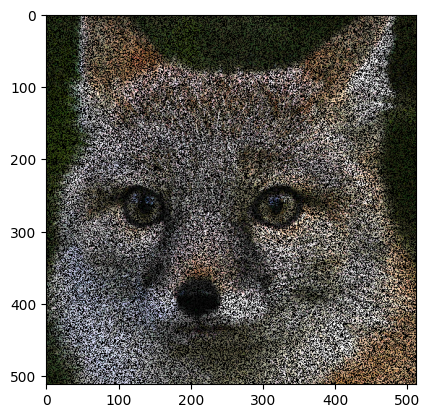

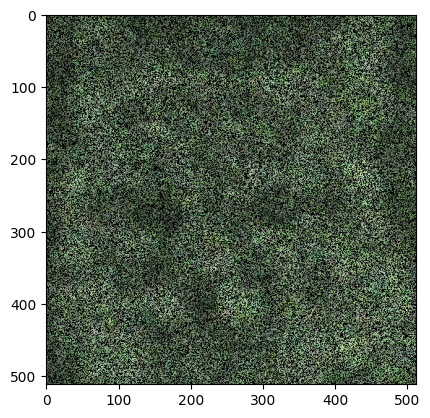

In [11]:
mask = torch.bernoulli(torch.ones((512,512))*0.5).to(bool)

plt.imshow((fox_reshaped * mask)[0].permute(1,2,0))

plt.figure()
plt.imshow((degraded_fox_reshaped * mask)[0].permute(1,2,0))

In [12]:
ssim = StructuralSimilarityIndexMeasure(data_range=1.0)
print(ssim(degraded_fox_reshaped, fox_reshaped))
print(ssim(degraded_fox_reshaped*mask, fox_reshaped*mask))

tensor(0.2776)
tensor(0.8356)


In [ ]:
degraded_fox_reshaped[0,0,0,0] = float("nan")

In [ ]:
fox_reshaped[:,:,~mask] = float("nan")

In [ ]:
mask.sum()

In [ ]:
#preds = torch.rand([3, 3, 256, 256])

target = preds * 0.75



ssim(preds, target)

In [ ]:
preds.shape

In [ ]:
preds = torch.rand([3, 3, 256, 256])

preds[0, 0, ::2, ::2] = 0

target = preds * 0.75

ssim = StructuralSimilarityIndexMeasure(data_range=1.0)

ssim(preds, target)

In [ ]:
preds = torch.rand([3, 3, 256, 256])

preds = preds[:, :, ::2, ::2]

target = preds * 0.75

ssim = StructuralSimilarityIndexMeasure(data_range=1.0)

ssim(preds, target)